# Telecom Tower Failure: Feature Engineering

**Aim:** Preprocess and feature-engineer a telecom tower failure dataset, ending at a processed dataset ready for ML.

```
Raw Data → Exploration → Cleaning → Feature Engineering → Encoding → X / y → Processed CSV
```

- **Features** = information used to predict (temperature, battery, power...)
- **Target** = what we predict → `Failure_Within_48Hrs`

> Works in Google Colab and locally. If you don't upload `telecom_tower_failure.csv`, a synthetic dataset with the same columns is generated so every cell still runs.

## 1. Import libraries
Pandas → tables, NumPy → numeric maths, Matplotlib → plots.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: False


## 2. Upload dataset
In Colab, select `telecom_tower_failure.csv` when the file picker appears. Cancel it to use synthetic data.

In [2]:
CSV_NAME = "telecom_tower_failure.csv"

if IN_COLAB and not os.path.exists(CSV_NAME):
    uploaded = files.upload()

if not os.path.exists(CSV_NAME):
    print("No CSV found, generating a synthetic dataset with the same columns.")
    rng = np.random.default_rng(42)
    n = 1000
    temp = rng.normal(52, 10, n)
    batt = rng.normal(48, 4, n)
    traffic = rng.gamma(2.0, 30, n)
    age = rng.integers(0, 15, n)
    risk = 0.08*(temp-52) - 0.25*(batt-48) + 0.1*(age-7) - 2.2
    fail = (rng.random(n) < 1/(1+np.exp(-risk))).astype(int)
    syn = pd.DataFrame({
        "Tower_ID": [f"T{i:04d}" for i in range(1, n+1)],
        "Temperature_C": temp.round(1),
        "Battery_Voltage": batt.round(1),
        "Power_Consumption_W": (200 + 2.5*traffic + rng.normal(0, 25, n)).round(1),
        "Signal_Strength_Percent": rng.uniform(40, 100, n).round(1),
        "Fan_Speed_RPM": rng.normal(3000, 400, n).round(0),
        "Humidity_Percent": rng.uniform(20, 95, n).round(1),
        "Traffic_Load": traffic.round(1),
        "Tower_Age_Years": age,
        "Failure_Within_48Hrs": fail,
    })
    # inject ~3% missing values into some numeric columns
    for col in ["Temperature_C", "Battery_Voltage", "Humidity_Percent", "Fan_Speed_RPM"]:
        syn.loc[rng.choice(n, int(0.03*n), replace=False), col] = np.nan
    syn.to_csv(CSV_NAME, index=False)

No CSV found, generating a synthetic dataset with the same columns.


## 3. Load the dataset
`pd.read_csv()` reads the CSV into a DataFrame; `head()` shows the first five rows.

In [3]:
df = pd.read_csv("telecom_tower_failure.csv")
df.head()

,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs
0,T0001,55.0,47.8,286.6,79.6,3048.0,25.0,34.5,5,0
1,T0002,41.6,45.1,407.3,99.4,3178.0,46.2,68.8,11,0
2,T0003,59.5,46.3,336.3,80.2,2840.0,93.9,46.4,4,1
3,T0004,61.4,50.5,498.9,71.5,3336.0,33.7,111.6,4,0
4,T0005,32.5,48.0,285.9,71.3,3060.0,NaN,15.3,13,0


## 4. Dataset size

In [4]:
df.shape

(1000, 10)

## 5. Column names

In [5]:
df.columns

Index(['Tower_ID', 'Temperature_C', 'Battery_Voltage', 'Power_Consumption_W',
       'Signal_Strength_Percent', 'Fan_Speed_RPM', 'Humidity_Percent',
       'Traffic_Load', 'Tower_Age_Years', 'Failure_Within_48Hrs'],
      dtype='str')

## 6. Data types
Temperature/Battery → float, Tower_Age_Years and the target → integer.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Tower_ID                 1000 non-null   str    
 1   Temperature_C            970 non-null    float64
 2   Battery_Voltage          970 non-null    float64
 3   Power_Consumption_W      1000 non-null   float64
 4   Signal_Strength_Percent  1000 non-null   float64
 5   Fan_Speed_RPM            970 non-null    float64
 6   Humidity_Percent         970 non-null    float64
 7   Traffic_Load             1000 non-null   float64
 8   Tower_Age_Years          1000 non-null   int64  
 9   Failure_Within_48Hrs     1000 non-null   int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 78.3 KB


## 7. Statistical summary
count, mean, std, min, quartiles, max.

In [7]:
df.describe()

,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs
count,970.000000,970.000000,1000.00000,1000.000000,970.000000,970.000000,1000.000000,1000.000000,1000.000000
mean,51.667526,47.675773,356.52840,70.351900,2997.477320,57.985361,62.048700,7.125000,0.181000
std,9.930821,4.076452,111.08359,17.190335,391.552047,21.607006,43.583743,4.365138,0.385211
min,15.500000,35.800000,159.80000,40.100000,1793.000000,20.200000,0.900000,0.000000,0.000000
25%,45.000000,45.025000,279.27500,56.300000,2747.000000,38.900000,30.050000,3.000000,0.000000
50%,51.950000,47.800000,335.85000,71.050000,2992.500000,59.250000,53.600000,7.000000,0.000000
75%,57.900000,50.500000,407.70000,84.500000,3256.250000,76.000000,82.125000,11.000000,0.000000
max,83.800000,59.700000,934.80000,100.000000,4610.000000,94.900000,286.800000,14.000000,1.000000


## 8. Check missing values
Missing data can break model training, so we find it first.

In [8]:
df.isnull().sum()

Tower_ID                    0
Temperature_C              30
Battery_Voltage            30
Power_Consumption_W         0
Signal_Strength_Percent     0
Fan_Speed_RPM              30
Humidity_Percent           30
Traffic_Load                0
Tower_Age_Years             0
Failure_Within_48Hrs        0
dtype: int64

## 9. Handle missing values (median)
Median is less affected by extremes than the mean. For `40, 42, 45, 47, 100` the median is **45**, while the mean (54.8) is dragged up by 100.

In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

Tower_ID                   0
Temperature_C              0
Battery_Voltage            0
Power_Consumption_W        0
Signal_Strength_Percent    0
Fan_Speed_RPM              0
Humidity_Percent           0
Traffic_Load               0
Tower_Age_Years            0
Failure_Within_48Hrs       0
dtype: int64

## 10. Feature engineering
Creating new useful variables from existing ones. Four features follow.

### Feature 1: High_Temperature
Temp > 60°C → 1, else 0 (binary feature).

In [10]:
df["High_Temperature"] = np.where(df["Temperature_C"] > 60, 1, 0)
df[["Temperature_C", "High_Temperature"]].head()

,Temperature_C,High_Temperature
0,55.0,0
1,41.6,0
2,59.5,0
3,61.4,1
4,32.5,0


### Feature 2: Low_Battery
Battery < 45V → 1, else 0.

In [11]:
df["Low_Battery"] = np.where(df["Battery_Voltage"] < 45, 1, 0)
df[["Battery_Voltage", "Low_Battery"]].head()

,Battery_Voltage,Low_Battery
0,47.8,0
1,45.1,0
2,46.3,0
3,50.5,0
4,48.0,0


### Feature 3: Power_Traffic_Ratio
Power ÷ Traffic. The `+ 0.01` prevents division by zero. This is a *ratio feature*.

In [12]:
df["Power_Traffic_Ratio"] = df["Power_Consumption_W"] / (df["Traffic_Load"] + 0.01)
df[["Power_Consumption_W", "Traffic_Load", "Power_Traffic_Ratio"]].head()

,Power_Consumption_W,Traffic_Load,Power_Traffic_Ratio
0,286.6,34.5,8.304839
1,407.3,68.8,5.919198
2,336.3,46.4,7.246283
3,498.9,111.6,4.470030
4,285.9,15.3,18.674069


### Feature 4: Tower_Age_Category
0–3 → New, 3–7 → Medium, >7 → Old. Turns a numeric variable into a categorical one.

> Note: `pd.cut` bins are right-closed, so an age of exactly 0 would become `NaN` and later get all-zero dummies. `include_lowest=True` fixes that (a small addition to the handout code).

In [13]:
df["Tower_Age_Category"] = pd.cut(
    df["Tower_Age_Years"],
    bins=[0, 3, 7, np.inf],
    labels=["New", "Medium", "Old"],
    include_lowest=True
)
print("Unassigned categories:", df["Tower_Age_Category"].isnull().sum())
df[["Tower_Age_Years", "Tower_Age_Category"]].head()

Unassigned categories: 0


,Tower_Age_Years,Tower_Age_Category
0,5,Medium
1,11,Old
2,4,Medium
3,4,Medium
4,13,Old


## 11. One-hot encoding
Mapping New=1, Medium=2, Old=3 would wrongly imply Old is "greater" than Medium. One-hot encoding gives each category its own 0/1 column instead.

| Category | New | Medium | Old |
|---|---|---|---|
| New | 1 | 0 | 0 |
| Medium | 0 | 1 | 0 |
| Old | 0 | 0 | 1 |

In [14]:
df = pd.get_dummies(df, columns=["Tower_Age_Category"], dtype=int)
df.head()

,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,T0001,55.0,47.8,286.6,79.6,3048.0,25.00,34.5,5,0,0,0,8.304839,0,1,0
1,T0002,41.6,45.1,407.3,99.4,3178.0,46.20,68.8,11,0,0,0,5.919198,0,0,1
2,T0003,59.5,46.3,336.3,80.2,2840.0,93.90,46.4,4,1,0,0,7.246283,0,1,0
3,T0004,61.4,50.5,498.9,71.5,3336.0,33.70,111.6,4,0,1,0,4.470030,0,1,0
4,T0005,32.5,48.0,285.9,71.3,3060.0,59.25,15.3,13,0,0,0,18.674069,0,0,1


## 12. Remove Tower_ID
It's just an identifier, not a predictive signal.

In [15]:
df = df.drop(columns=["Tower_ID"])
df.columns.tolist()

['Temperature_C',
 'Battery_Voltage',
 'Power_Consumption_W',
 'Signal_Strength_Percent',
 'Fan_Speed_RPM',
 'Humidity_Percent',
 'Traffic_Load',
 'Tower_Age_Years',
 'Failure_Within_48Hrs',
 'High_Temperature',
 'Low_Battery',
 'Power_Traffic_Ratio',
 'Tower_Age_Category_New',
 'Tower_Age_Category_Medium',
 'Tower_Age_Category_Old']

## 13. Separate features (X) and target (y)
`X` = inputs, `y` = what we predict.

In [16]:
X = df.drop(columns=["Failure_Within_48Hrs"])
y = df["Failure_Within_48Hrs"]
X.head()

,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,55.0,47.8,286.6,79.6,3048.0,25.00,34.5,5,0,0,8.304839,0,1,0
1,41.6,45.1,407.3,99.4,3178.0,46.20,68.8,11,0,0,5.919198,0,0,1
2,59.5,46.3,336.3,80.2,2840.0,93.90,46.4,4,0,0,7.246283,0,1,0
3,61.4,50.5,498.9,71.5,3336.0,33.70,111.6,4,1,0,4.470030,0,1,0
4,32.5,48.0,285.9,71.3,3060.0,59.25,15.3,13,0,0,18.674069,0,0,1


## 14. Check X and y

In [17]:
print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])
print("Target size:", y.shape[0])

Number of features: 14
Number of records: 1000
Target size: 1000


## 15. Target distribution
0 → no failure, 1 → failure. If almost everything is 0, the dataset is **imbalanced**.

Failure_Within_48Hrs
0    819
1    181
Name: count, dtype: int64


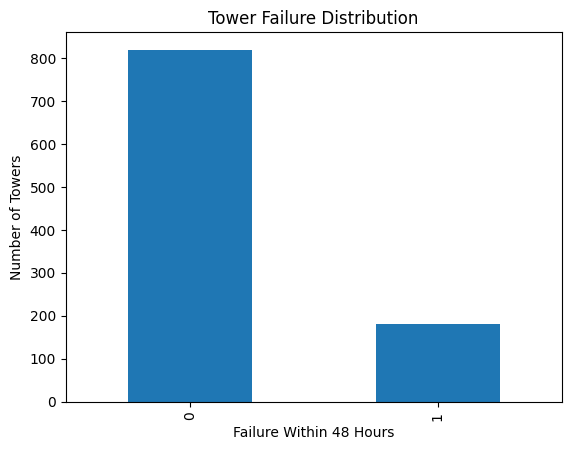

In [18]:
print(y.value_counts())

y.value_counts().plot(kind="bar")
plt.xlabel("Failure Within 48 Hours")
plt.ylabel("Number of Towers")
plt.title("Tower Failure Distribution")
plt.show()

## 16. Save the feature-engineered dataset

In [19]:
df.to_csv("telecom_tower_feature_engineered.csv", index=False)
df.head()

,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,55.0,47.8,286.6,79.6,3048.0,25.00,34.5,5,0,0,0,8.304839,0,1,0
1,41.6,45.1,407.3,99.4,3178.0,46.20,68.8,11,0,0,0,5.919198,0,0,1
2,59.5,46.3,336.3,80.2,2840.0,93.90,46.4,4,1,0,0,7.246283,0,1,0
3,61.4,50.5,498.9,71.5,3336.0,33.70,111.6,4,0,1,0,4.470030,0,1,0
4,32.5,48.0,285.9,71.3,3060.0,59.25,15.3,13,0,0,0,18.674069,0,0,1


## 17. Download the processed dataset
Downloads to your computer when running in Colab.

In [20]:
if IN_COLAB:
    files.download("telecom_tower_feature_engineered.csv")
else:
    print("Not in Colab: file saved as telecom_tower_feature_engineered.csv in the working directory.")
print("\nFeature engineering completed successfully!")

Not in Colab: file saved as telecom_tower_feature_engineered.csv in the working directory.

Feature engineering completed successfully!


## Complete workflow
```
RAW DATA → telecom_tower_failure.csv
   ↓ Load with Pandas
   ↓ Data Exploration
   ↓ Missing Value Handling
   ↓ Feature Engineering: High_Temperature, Low_Battery, Power_Traffic_Ratio, Tower_Age_Category
   ↓ One-Hot Encoding
   ↓ Remove Tower_ID
   ↓ X and y
   ↓ Feature-Engineered CSV
   ↓ Random Forest Training  (NEXT PRACTICAL)
```

## Quick viva answers
1. **Why Colab/SageMaker?** A development environment for ML.
2. **What is a feature?** Input information used by the model.
3. **What is feature engineering?** Creating or transforming useful features from raw data.
4. **Why encoding?** Converts categories into numbers without implying a false order.
5. **Why X and y?** X holds the inputs, y holds the value to predict.